# 窒素の0次元プラズマ反応計算 — 基本実行

ZDPlasKinと同じ **窒素21種・96反応、SIGLO N₂の25衝突過程**を、接続済みのPy3bolosとSciPyで計算します。

上から順に実行してください。「2. 計算条件」のセルで、E/N・温度・圧力・初期電子密度・計算時間・エネルギー格子数を変更できます。

既定条件は **1000 Td、300 K、101325 Pa、初期電子・N₂⁺各10¹⁴ m⁻³、連続印加1 ns** です。
元のフォルダ名と一部コメントには10 nsとありますが、保存済み実行の設定値に合わせて1 nsとします。

局所電界近似（LFA）により定常EEDFから係数を求め、密度をBDF法で時間積分します。
純N₂の基底状態だけを電子衝突標的とするため、一定E/N・一定Tgでは衝突標的の組成は1のままで、係数も一定です。
第三体 `ANY_NEUTRAL` には時間変化する全中性種密度を使います。

電子エネルギー方程式・電子間衝突・超弾性衝突・気体加熱は含みません。
元ZDPlasKinの高電離時の計算とは電子間衝突の扱いが異なります。
このノートブックは **E/N > 0の連続印加** 用です。

## 1. ライブラリとプロジェクトの読み込み

NumPy・SciPy・Matplotlib・IPythonが使えるPythonカーネルを選んでください。
BOLOSは隣接する `Py3bolos/` のクローンから直接読み込みます。

In [1]:
from importlib import import_module
from pathlib import Path
import csv
import hashlib
import json
import re
import sys

import numpy as np
import scipy
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# ノートブックのフォルダ、ワークスペースのルートのどちらからでも起動できます。
model_candidates = []
for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
    model_candidates.extend([base, base / "Py3ZDPlasChem-master"])
MODEL_DIR = next(
    (
        path
        for path in model_candidates
        if (path / "samples/zdplaskin/nitrogen/kinet.inp").is_file()
        and (path / "bolos_coupling.py").is_file()
    ),
    None,
)
if MODEL_DIR is None:
    raise FileNotFoundError(
        "Py3ZDPlasChemのフォルダ内、またはワークスペースのルートから開いてください。"
    )
if str(MODEL_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_DIR))

ArchiveMechanism = import_module("compare_zdplaskin").ArchiveMechanism
solve_archive_swarm = import_module("compare_zdplaskin").solve_archive_swarm
KB = import_module("kinetics").KB
KB_EV = import_module("kinetics").KB_EV
bolos_solver = import_module("bolos").solver

SAMPLE_DIR = MODEL_DIR / "samples/zdplaskin/nitrogen"
print("Python :", sys.executable)
print("NumPy  :", np.__version__)
print("SciPy  :", scipy.__version__)
print("BOLOS  :", Path(bolos_solver.__file__).resolve())
print("入力先 :", SAMPLE_DIR)
calculate_current = import_module("current_diagnostics").calculate_current
reduced_field_to_electric_field = import_module(
    "current_diagnostics"
).reduced_field_to_electric_field
plot_current_result = import_module("current_diagnostics").plot_current_result
save_current_result = import_module("current_diagnostics").save_current_result


Python : c:\Users\daiko\Documents\Python_venvSystem\3.14system\Py3ZDPlasChem\env_Py3ZDPlasChem\Scripts\python.exe
NumPy  : 2.5.4
SciPy  : 1.18.1
BOLOS  : C:\Users\daiko\Documents\Python_venvSystem\3.14system\Py3ZDPlasChem\Py3ZDPlasChem-master\Py3bolos\bolos\solver.py
入力先 : C:\Users\daiko\Documents\Python_venvSystem\3.14system\Py3ZDPlasChem\Py3ZDPlasChem-master\samples\zdplaskin\nitrogen


## 2. 計算条件

密度は **m⁻³**、時間設定は **ns** です。元のZDPlasKinで指定された初期電子密度10⁸ cm⁻³は、ここでは10¹⁴ m⁻³とします。
圧力は初期の基底N₂密度 `p/(kB*Tg)` を決めます。計算中の圧力を一定に保つ制御は行いません。

`BOLOS_CELLS` は電子エネルギー格子数です。1600→3200などに増やして反応係数・密度の変化を確認できます。
`POINTS` は保存・描画の出力点数であり、BDF内部の時間刻みやBOLOSの格子数とは異なります。

In [2]:
FIELD_TD = 1000.0  # E/N [Td]：計算終了まで連続印加
GAS_TEMPERATURE_K = 300.0  # 一定の気体温度 [K]
PRESSURE_PA = 101325.0  # 初期基底N2密度を決める圧力 [Pa]
SEED_DENSITY_M3 = 1.0e8  # 初期電子密度 [m^-3]：N2+も同じ値
END_NS = 1.0  # 計算終了時刻 [ns]
POINTS = 10001  # 初期時刻を含む出力点数

BOLOS_CELLS = 200  # 電子エネルギー格子数：800/1600/3200等で比較
CHEMISTRY_RTOL = 1.0e-8  # 化学反応のBDF相対許容誤差
ATOL_DENSITY_M3 = 1.0e-4  # BDF絶対許容誤差 [m^-3]

PLOT_SPECIES = ["E", "N2^+", "N2(C3)", "N"]
SAVE_RESULTS = True
OUTPUT_DIR = MODEL_DIR / "output_notebook_nitrogen"

for label, value in {
    "FIELD_TD": FIELD_TD,
    "GAS_TEMPERATURE_K": GAS_TEMPERATURE_K,
    "PRESSURE_PA": PRESSURE_PA,
    "SEED_DENSITY_M3": SEED_DENSITY_M3,
    "END_NS": END_NS,
    "ATOL_DENSITY_M3": ATOL_DENSITY_M3,
}.items():
    if not np.isfinite(value) or value <= 0:
        raise ValueError(f"{label}には正の有限値を指定してください。")
if not isinstance(POINTS, (int, np.integer)) or POINTS < 2:
    raise ValueError("POINTSは2以上の整数にしてください。")
if not isinstance(BOLOS_CELLS, (int, np.integer)) or BOLOS_CELLS < 50:
    raise ValueError("BOLOS_CELLSは50以上の整数にしてください。")
if not 0 < CHEMISTRY_RTOL < 1:
    raise ValueError("CHEMISTRY_RTOLは0より大きく1未満にしてください。")

# 電流計算の幾何とイオン移動度。未定値に実機の数値を仮定しません。
DISCHARGE_AREA_M2 = None  # 電流が通る断面積 [m^2]。Noneなら電流密度のみ
ELECTRODE_GAP_M = None  # 電極間距離 [m]。入力時は電界から電圧も出力
ION_MOBILITIES_M2_V_S = {}  # 例：キー 'N2^+', 'N^+', 'N3^+', 'N4^+'
# 値は正の移動度 [m^2/(V s)]（スカラーまたは時刻と同じ長さの配列）。
# 全ての存在するイオンの値が揃った場合にだけ、総電流を出力します。


## 3. 反応入力と断面積の確認

元データの出典・SHA-256を照合し、粒子種を `kinet.inp` から読み込みます。
反応係数は既存の化学計算コードと同じ読み込み・SI変換を使用します。
入力ファイルの内容は変更しません。

In [3]:
provenance = json.loads(
    (SAMPLE_DIR / "provenance.json").read_text(encoding="utf-8")
)
for item in provenance:
    path = SAMPLE_DIR / item["local_file"]
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    if digest != item["sha256"]:
        raise ValueError(f"元データと一致しない入力があります：{path}")

mechanism_text = (SAMPLE_DIR / "kinet.inp").read_text(encoding="utf-8")
species_block = re.search(r"(?ms)^SPECIES\s*\n(.*?)^END\s*$", mechanism_text)
if species_block is None:
    raise ValueError("kinet.inpのSPECIESブロックがありません。")
species = (
    " ".join(line.split("#")[0] for line in species_block[1].splitlines())
    .upper()
    .split()
)
print(f"粒子種数：{len(species)}")
print(", ".join(species))
print("断面積：", SAMPLE_DIR / "bolsigdb.dat")
print("入力のSHA-256照合：成功")


粒子種数：21
E, N2, N2^+, N2(V1), N2(V2), N2(V3), N2(V4), N2(V5), N2(V6), N2(V7), N2(V8), N2(A3), N2(B3), N2(A1L), N2(C3), N, N(2D), N(2P), N^+, N3^+, N4^+
断面積： C:\Users\daiko\Documents\Python_venvSystem\3.14system\Py3ZDPlasChem\Py3ZDPlasChem-master\samples\zdplaskin\nitrogen\bolsigdb.dat
入力のSHA-256照合：成功


## 4. Py3bolosで定常EEDF・電子衝突係数を計算

接続済みの共通処理を呼び出します。初期の線形格子から、平均エネルギーに基づく上限の二次格子へ移します。
この処理のBOLOS反復許容誤差は1e-6です。`CHEMISTRY_RTOL` はこの反復許容誤差を変更しません。

計算中にEEDF末尾の傾きに関する警告が出る場合があります。
反復誤差だけで格子収束とは判断せず、必要な精度に合わせて格子数を変えて比較してください。

In [4]:
swarm_rates, swarm_diagnostics, collisions = solve_archive_swarm(
    SAMPLE_DIR / "bolsigdb.dat",
    FIELD_TD,
    GAS_TEMPERATURE_K,
    cells=BOLOS_CELLS,
    target="N2",
)
mean_energy_eV = swarm_diagnostics["mean_energy_eV"]
electron_temperature_K = 2 * mean_energy_eV / (3 * KB_EV)
print(f"衝突過程数       ：{len(collisions)}")
print(f"平均電子エネルギー：{mean_energy_eV:.8g} eV")
print(f"有効電子温度     ：{electron_temperature_K:.8g} K")
print(f'電離係数         ：{swarm_rates["N2->N2^+"]:.9e} m^3/s')
print(f'BOLOS反復誤差    ：{swarm_diagnostics["error"]:.3e}')


衝突過程数       ：25
平均電子エネルギー：15.922211 eV
有効電子温度     ：123179.73 K
電離係数         ：1.013702564e-14 m^3/s
BOLOS反復誤差    ：6.858e-07


## 5. 96反応を組み立て、全粒子種の密度を積分

反応次数に従ってcm単位の係数をSIへ換算し、窒素原子数と電荷を保存するか検査します。
初期値は元のZDPlasKinと同様に、基底N₂に電子・N₂⁺の等量シードを追加します。
係数を固定し、全21種の密度を解きます。電子密度を手動で固定する処理はありません。

In [5]:
conditions = {
    "field_td": float(FIELD_TD),
    "temperature_k": float(GAS_TEMPERATURE_K),
    "pressure_pa": float(PRESSURE_PA),
    "end_time_s": float(END_NS * 1e-9),
}
mechanism = ArchiveMechanism(
    SAMPLE_DIR / "kinet.inp",
    species,
    conditions,
    swarm_rates,
    mean_energy_eV,
    expected_counts=(21, 96),
)
index = mechanism.index
if SEED_DENSITY_M3 >= mechanism.n0:
    raise ValueError("初期電子密度は初期基底N2密度より小さくしてください。")
initial_density_m3 = np.zeros(len(species))
initial_density_m3[index["N2"]] = mechanism.n0
initial_density_m3[index["E"]] = SEED_DENSITY_M3
initial_density_m3[index["N2^+"]] = SEED_DENSITY_M3
time_s = np.linspace(0, conditions["end_time_s"], POINTS)

solution = solve_ivp(
    mechanism.rhs,
    (0, time_s[-1]),
    initial_density_m3 / mechanism.n0,
    method="BDF",
    jac=mechanism.jac,
    t_eval=time_s,
    rtol=CHEMISTRY_RTOL,
    atol=ATOL_DENSITY_M3 / mechanism.n0,
)
if not solution.success:
    raise RuntimeError(solution.message)
density_m3 = solution.y * mechanism.n0
if (
    not np.isfinite(density_m3).all()
    or density_m3.min() < -100 * ATOL_DENSITY_M3
):
    raise RuntimeError("非有限密度または許容誤差を超える負密度があります。")
print(f"完了：{len(species)}種・{len(mechanism.k)}反応・{len(time_s)}出力点")
print(f"初期基底N2密度：{mechanism.n0:.9e} m^-3")
print(f"RHS評価回数：{solution.nfev}")


完了：21種・96反応・10001出力点
初期基底N2密度：2.446313292e+25 m^-3
RHS評価回数：3043


## 6. 保存則とモデルの診断

窒素原子数の相対誤差、初期気体密度で規格化した電荷残差、最小密度を確認します。
電離率と、電子衝突標的に含めていない中性種の割合も表示します。
これらの保存則が良好でも、省略した衝突過程や固定温度の近似の妥当性まで保証するものではありません。

In [6]:
atom_totals = mechanism.atoms @ density_m3
charge_totals = mechanism.charge @ density_m3
neutral_total = density_m3[mechanism.neutral].sum(axis=0)
unsupported_neutrals = density_m3[
    mechanism.neutral & (np.array(species) != "N2")
].sum(axis=0)
ion_fraction = density_m3[mechanism.charge > 0].sum(axis=0) / mechanism.n0
unsupported_fraction = unsupported_neutrals / np.maximum(
    neutral_total, np.finfo(float).tiny
)
diagnostics = {
    "species_count": len(species),
    "reaction_count": len(mechanism.k),
    "max_atom_relative_error": float(
        np.max(np.abs(atom_totals / atom_totals[0] - 1))
    ),
    "max_charge_residual_over_initial_density": float(
        np.max(np.abs(charge_totals)) / mechanism.n0
    ),
    "minimum_density_m3": float(density_m3.min()),
    "maximum_electron_density_m3": float(density_m3[index["E"]].max()),
    "max_ion_fraction_over_initial_density": float(ion_fraction.max()),
    "max_unsupported_neutral_fraction": float(unsupported_fraction.max()),
    "rhs_evaluations": int(solution.nfev),
}
print(json.dumps(diagnostics, ensure_ascii=False, indent=2))
assert diagnostics["max_atom_relative_error"] < 1e-8
assert diagnostics["max_charge_residual_over_initial_density"] < 1e-8
display(
    Markdown(
        f"**最大電離率：{ion_fraction.max():.3%}、"
        "衝突標的に含めていない中性種の最大割合："
        f"{unsupported_fraction.max():.3%}。** "
        "高電離・強解離では、"
        "基底N₂だけを標的とし電子間衝突を省略するモデルの適用範囲を確認してください。"
    )
)


{
  "species_count": 21,
  "reaction_count": 96,
  "max_atom_relative_error": 1.3322676295501878e-15,
  "max_charge_residual_over_initial_density": 1.2180606997465345e-16,
  "minimum_density_m3": 0.0,
  "maximum_electron_density_m3": 3.0926643555681665e+24,
  "max_ion_fraction_over_initial_density": 0.1264214344885517,
  "max_unsupported_neutral_fraction": 0.9983776205719235,
  "rhs_evaluations": 3043
}


**最大電離率：12.642%、衝突標的に含めていない中性種の最大割合：99.838%。** 高電離・強解離では、基底N₂だけを標的とし電子間衝突を省略するモデルの適用範囲を確認してください。

## 7. 密度の時間変化を描画

基底N₂と、選択した粒子を別のパネルに描きます。横軸はns、縦軸はm⁻³です。
対数表示では非正値を描画から除きますが、計算値・保存値のクリップは行いません。
`PLOT_SPECIES` には「3. 反応入力と断面積の確認」で表示した粒子名を指定できます。

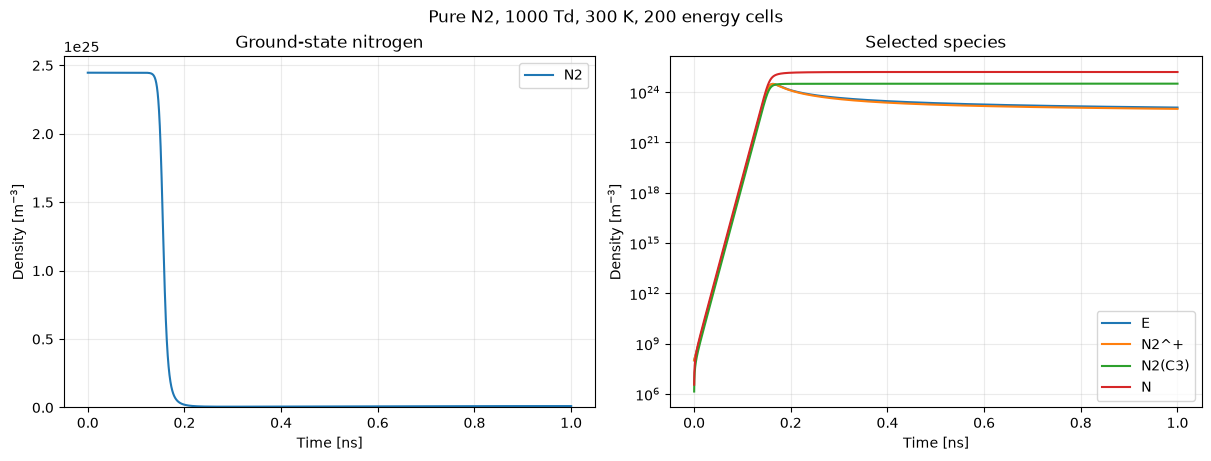

In [7]:
unknown_species = [name for name in PLOT_SPECIES if name.upper() not in index]
if unknown_species:
    raise ValueError(f"未定義の描画粒子があります：{unknown_species}")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
axes[0].plot(
    time_s * 1e9, density_m3[index["N2"]], color="tab:blue", label="N2"
)
axes[0].set(
    xlabel="Time [ns]",
    ylabel="Density [m$^{-3}$]",
    title="Ground-state nitrogen",
)
axes[0].set_ylim(bottom=0)
axes[0].legend()
for name in PLOT_SPECIES:
    values = density_m3[index[name.upper()]]
    axes[1].semilogy(
        time_s * 1e9, np.where(values > 0, values, np.nan), label=name
    )
axes[1].set(
    xlabel="Time [ns]", ylabel="Density [m$^{-3}$]", title="Selected species"
)
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.25)
fig.suptitle(
    f"Pure N2, {FIELD_TD:g} Td, {GAS_TEMPERATURE_K:g} K, {BOLOS_CELLS} energy"
    " cells"
)
plt.show()


## 8. 伝導電流・変位電流の後処理

一様な電界・一様な断面積を仮定して、通常の電流の向きを電界の正方向として計算します。

\[
J_e=e n_e\mu_e E,\quad
J_i=e\sum_i |z_i|n_i\mu_i E,\quad
J_d=\epsilon_0\frac{dE}{dt},\qquad
I_{\mathrm{total}}=A(J_e+J_i+J_d).
\]

BOLOSが返すのは換算移動度 \(\mu_e N\) です。\(\mu_e=(\mu_e N)/N\) とし、
\(E=(E/N)\,N\) の換算と同じNを使用します。本例では、BOLOSの衝突標的に合わせて **各時刻の基底N₂密度** をNとします。
このため、N₂が減少するとE/N一定でもEと換算電圧は変化します。
**一定印加電圧を仮定した計算とは異なります。** 電界・回路・シースを自己無撞着に解く処理は追加していません。

- `DISCHARGE_AREA_M2` が未入力なら、電流密度［A/m²］を表示します。入力すると電流［A］へ換算します。
- イオン移動度の不足がある場合、電子・既知イオン・変位電流のみを表示し、**総電流という名称の出力は作りません**。
- 電子と正イオンは逆向きに移動するため、電気的中性でも伝導電流は相殺されません。
- 変位電流は保存されたEの時間微分から求めます。t=0より前の立ち上がり、理想ステップのピーク、配線の寄生容量は含みません。

これは密度計算後の診断です。粒子の輸送損失や壁面での失活は密度方程式へ追加しません。

BOLOS換算電子移動度 [1/(V m s)]： 6.498635332952165e+23
断面積が未入力のため、電流密度 [A/m^2] を表示します。
移動度が未入力のイオン： ['N2^+', 'N^+', 'N3^+', 'N4^+']
総電流は未算出です。グラフの合計は既知成分のみです。


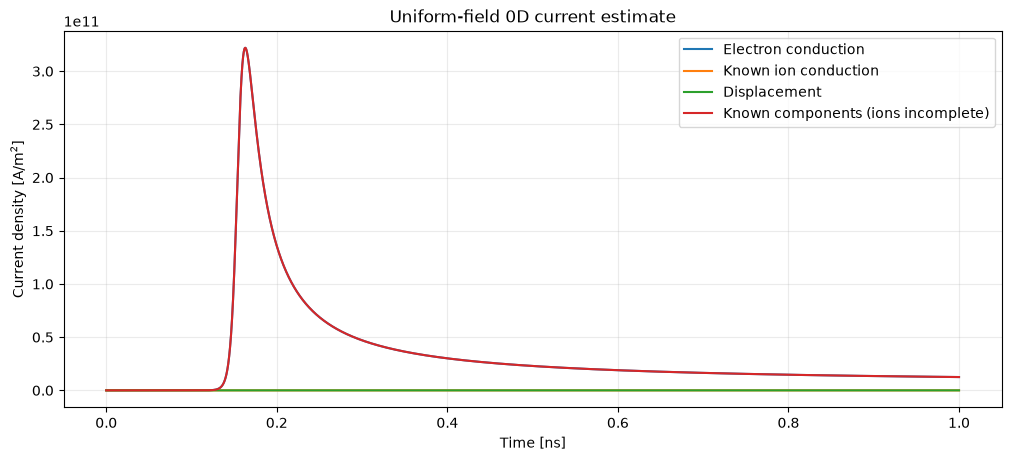

In [8]:
field_reference_density_m3 = density_m3[index["N2"]]
electric_field_V_m = reduced_field_to_electric_field(
    FIELD_TD, field_reference_density_m3
)
current_result = calculate_current(
    time_s,
    density_m3,
    species,
    mechanism.charge,
    electric_field_V_m,
    swarm_diagnostics["electron_reduced_mobility_1_V_m_s"],
    field_reference_density_m3,
    ion_mobilities_m2_V_s=ION_MOBILITIES_M2_V_S,
    area_m2=DISCHARGE_AREA_M2,
    electrode_gap_m=ELECTRODE_GAP_M,
    negative_density_tolerance_m3=100 * ATOL_DENSITY_M3,
)
print(
    "BOLOS換算電子移動度 [1/(V m s)]：",
    swarm_diagnostics["electron_reduced_mobility_1_V_m_s"],
)
if DISCHARGE_AREA_M2 is None:
    print("断面積が未入力のため、電流密度 [A/m^2] を表示します。")
if current_result.total_available:
    quantity = (
        "total_current_A"
        if DISCHARGE_AREA_M2 is not None
        else "total_current_density_A_m2"
    )
    print(
        quantity,
        "の最大絶対値：",
        np.max(np.abs(current_result.traces[quantity])),
    )
else:
    print(
        "移動度が未入力のイオン：",
        current_result.metadata["missing_ion_mobilities"],
    )
    print("総電流は未算出です。グラフの合計は既知成分のみです。")
current_fig = plot_current_result(current_result)
plt.show()


## 9. 計算結果の保存

`SAVE_RESULTS = True` のとき、全粒子種のCSV・NPZ、SI反応係数、条件・診断・入力ハッシュ、グラフを `OUTPUT_DIR` に保存します。
同じ出力先で再実行すると、そのフォルダ内の同名ファイルを更新します。
格子比較では `OUTPUT_DIR` を格子数ごとに変えると結果を残せます。

In [9]:
if SAVE_RESULTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    np.savetxt(
        OUTPUT_DIR / "densities.csv",
        np.column_stack((time_s, density_m3.T)),
        delimiter=",",
        header="time_s," + ",".join(species),
        comments="",
    )
    np.savez_compressed(
        OUTPUT_DIR / "densities.npz",
        time_s=time_s,
        densities_m3=density_m3,
        species=np.array(species),
        field_td=FIELD_TD,
        mean_energy_eV=mean_energy_eV,
    )
    with (OUTPUT_DIR / "coefficients.csv").open(
        "w", newline="", encoding="utf-8"
    ) as handle:
        writer = csv.writer(handle)
        writer.writerow(["reaction", "order", "coefficient_SI"])
        writer.writerows(
            zip(mechanism.equations, mechanism.orders, mechanism.k)
        )
    run_settings = dict(
        conditions,
        seed_density_m3=SEED_DENSITY_M3,
        points=POINTS,
        bolos_cells=BOLOS_CELLS,
        bolos_rtol=1e-6,
        chemistry_rtol=CHEMISTRY_RTOL,
        atol_density_m3=ATOL_DENSITY_M3,
    )
    report = {
        "settings": run_settings,
        "swarm": swarm_diagnostics,
        "diagnostics": diagnostics,
        "density_units": "m^-3",
        "time_units": "s",
        "python_executable": sys.executable,
        "python_version": sys.version,
        "numpy_version": np.__version__,
        "scipy_version": scipy.__version__,
        "bolos_source": str(Path(bolos_solver.__file__).resolve()),
        "inputs": provenance,
        "current": current_result.metadata,
        "model": (
            "LFA; fixed E/N and Tg; pure ground-state N2 target; no electron"
            " energy ODE, electron-electron or superelastic collisions, gas"
            " heating or transport."
        ),
    }
    (OUTPUT_DIR / "diagnostics.json").write_text(
        json.dumps(report, ensure_ascii=False, indent=2, allow_nan=False),
        encoding="utf-8",
    )
    fig.savefig(OUTPUT_DIR / "densities.png", dpi=160)
    save_current_result(current_result, OUTPUT_DIR)
    current_fig.savefig(OUTPUT_DIR / "current.png", dpi=160)
    print("保存先：", OUTPUT_DIR.resolve())
    print(
        "densities.csv / densities.npz / coefficients.csv / diagnostics.json /"
        " densities.png"
    )
    print("current.csv / current.npz / current_metadata.json / current.png")
else:
    print("SAVE_RESULTS=Falseのため、ファイルへは保存していません。")


保存先： C:\Users\daiko\Documents\Python_venvSystem\3.14system\Py3ZDPlasChem\Py3ZDPlasChem-master\output_notebook_nitrogen
densities.csv / densities.npz / coefficients.csv / diagnostics.json / densities.png
current.csv / current.npz / current_metadata.json / current.png


### 次に条件を変える場合

「2. 計算条件」を変更し、そのセル以降を再実行してください。入力ファイルを書き換える必要はありません。
格子比較は `BOLOS_CELLS=1600` と `3200` などで実行し、電離係数と電子密度軌道の変化を確認します。
密度CSV・NPZは描画の選択によらず全21種を保存します。

反応・断面積の出典とモデルの省略項は [窒素サンプルの説明](samples/zdplaskin/README.md)、
既存の対照計算は [検証結果](verification/README.md) を参照してください。